# Embedding geometry: why SCARSE wins where it wins

Mechanism behind the SCARSE-vs-baseline gap. For a few datasets where SCARSE is much better and a few where it is on par, we compare ESM-2 against the baselines on two geometric properties of the representation space:

1. **Spread** - mean pairwise distance between sequences (is the space collapsed or expanded?).
2. **Structure** - how well distance in representation space tracks difference in target value (Spearman between pairwise embedding distance and pairwise |target difference|). A representation is *learnable* for GPR when nearby points have similar targets.

The sharper signal is (2): ESM-2 winning should coincide with its space aligning distance with the property better than the baselines do.

**Needs a GPU** (ESM-2). Run on the cluster inside the container.

In [6]:
import sys, os
try:
    import analysis_common as ac
except ModuleNotFoundError:
    sys.path.insert(0, os.getcwd()); import analysis_common as ac
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
mpl.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print('repo root:', ac.ROOT)


repo root: /Users/leoan/Documents/GitHub/SCARSE-repro


In [7]:
# Embed sequences with a representation, reusing the pipeline's SequenceRepresenter
# so the features are IDENTICAL to what the benchmark/AL use.
def get_representer(representation):
    # Add a project functions/ dir to the path so we reuse the real code.
    for cand in ['code/workflow_simulation', 'code/selection_analysis',
                 os.path.join(ac.ROOT, 'code', 'workflow_simulation')]:
        fdir = cand if os.path.isabs(cand) else os.path.join(ac.ROOT, cand)
        if os.path.isdir(os.path.join(fdir, 'functions')):
            sys.path.insert(0, fdir); break
    from functions.representations import SequenceRepresenter
    rep = SequenceRepresenter(representation=representation, random_seed=42)
    rep.load_model()
    return rep

def embed(sequences, representation):
    rep = get_representer(representation)
    # n-gram needs a fit; for geometry we fit on the same set (illustrative only).
    try:
        return rep.transform(list(sequences), fit=True)
    except TypeError:
        return rep.transform(list(sequences))


In [8]:
# Pairwise geometry metrics for one embedding matrix vs its targets.
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr
rng = np.random.default_rng(0)
MAXN = 400   # cap sequences per dataset so pdist stays cheap

def geometry(emb, y):
    n = len(y)
    if n > MAXN:
        idx = rng.choice(n, MAXN, replace=False)
        emb, y = emb[idx], y[idx]
    d_emb = pdist(emb, metric='euclidean')
    d_lab = pdist(y.reshape(-1, 1), metric='euclidean')
    rho, _ = spearmanr(d_emb, d_lab)
    return {'mean_pairwise_dist': float(d_emb.mean()),
            'dist_label_rho': float(rho)}


In [9]:
# Choose datasets to contrast. Edit these to your high-gap / low-gap picks
# (read off Figure 2). Defaults: substitutions (SCARSE strong) vs AMP (on par).
HIGH_GAP = ['SOX30_HUMAN', 'DN7A_SACS2']      # SCARSE clearly ahead
LOW_GAP  = ['Ecoli_AMPs', 'Saureus_AMPs']   # closer to baselines
REPS = ['esm', 'pepbert', 'physchem', 'morgan', 'ngram']  # add 'pepbert' if cached
files = {**ac.PEPTIDE_FILES, **ac.SUBSTITUTION_FILES}

records = []
for group, names in [('high-gap', HIGH_GAP), ('low-gap', LOW_GAP)]:
    for name in names:
        df = ac.load_dataset(name, files=files)
        if df is None:
            continue
        y = (ac.direction_sign(name) * df['score'].values).astype(float)
        for rep in REPS:
            try:
                emb = embed(df['sequence'].values, rep)
            except Exception as e:
                print(f'[skip] {name}/{rep}: {type(e).__name__}: {e}'); continue
            g = geometry(emb, y)
            g.update({'group': group, 'Dataset': name, 'Representation': rep})
            records.append(g)
            print(name, rep, {k: round(v,3) for k,v in g.items() if isinstance(v,float)})
geo = pd.DataFrame(records)
if len(geo):
    geo.to_csv(os.path.join(ac.FIG_DIR, 'embedding_geometry.csv'), index=False)


Loading base pretrained ESM model: facebook/esm2_t33_650M_UR50D


Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['esm.pooler.dense.bias', 'esm.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ESM model loaded. Using device: cpu
SOX30_HUMAN esm {'mean_pairwise_dist': 0.446, 'dist_label_rho': 0.211}
Loading PepBERT model: dzjxzyd/PepBERT-large-UniParc
PepBERT model loaded. Using device: cpu
SOX30_HUMAN pepbert {'mean_pairwise_dist': 0.411, 'dist_label_rho': 0.167}
SOX30_HUMAN physchem {'mean_pairwise_dist': 44.834, 'dist_label_rho': 0.08}
SOX30_HUMAN morgan {'mean_pairwise_dist': 1.083, 'dist_label_rho': 0.079}
SOX30_HUMAN ngram {'mean_pairwise_dist': 0.841, 'dist_label_rho': 0.073}
Loading base pretrained ESM model: facebook/esm2_t33_650M_UR50D


Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['esm.pooler.dense.bias', 'esm.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ESM model loaded. Using device: cpu
DN7A_SACS2 esm {'mean_pairwise_dist': 0.466, 'dist_label_rho': 0.27}
Loading PepBERT model: dzjxzyd/PepBERT-large-UniParc
PepBERT model loaded. Using device: cpu
DN7A_SACS2 pepbert {'mean_pairwise_dist': 0.437, 'dist_label_rho': 0.109}
DN7A_SACS2 physchem {'mean_pairwise_dist': 50.697, 'dist_label_rho': 0.059}
DN7A_SACS2 morgan {'mean_pairwise_dist': 1.485, 'dist_label_rho': 0.068}
DN7A_SACS2 ngram {'mean_pairwise_dist': 0.827, 'dist_label_rho': 0.011}
Loading base pretrained ESM model: facebook/esm2_t33_650M_UR50D


Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['esm.pooler.dense.bias', 'esm.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ESM model loaded. Using device: cpu
Ecoli_AMPs esm {'mean_pairwise_dist': 3.835, 'dist_label_rho': 0.022}
Loading PepBERT model: dzjxzyd/PepBERT-large-UniParc
PepBERT model loaded. Using device: cpu
Ecoli_AMPs pepbert {'mean_pairwise_dist': 4.699, 'dist_label_rho': 0.052}
Ecoli_AMPs physchem {'mean_pairwise_dist': 936.727, 'dist_label_rho': 0.084}
Ecoli_AMPs morgan {'mean_pairwise_dist': 7.951, 'dist_label_rho': 0.017}
Ecoli_AMPs ngram {'mean_pairwise_dist': 1.353, 'dist_label_rho': 0.027}
Loading base pretrained ESM model: facebook/esm2_t33_650M_UR50D


Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['esm.pooler.dense.bias', 'esm.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ESM model loaded. Using device: cpu
Saureus_AMPs esm {'mean_pairwise_dist': 3.817, 'dist_label_rho': -0.011}
Loading PepBERT model: dzjxzyd/PepBERT-large-UniParc
PepBERT model loaded. Using device: cpu
Saureus_AMPs pepbert {'mean_pairwise_dist': 4.791, 'dist_label_rho': 0.035}
Saureus_AMPs physchem {'mean_pairwise_dist': 932.226, 'dist_label_rho': 0.075}
Saureus_AMPs morgan {'mean_pairwise_dist': 7.95, 'dist_label_rho': 0.033}
Saureus_AMPs ngram {'mean_pairwise_dist': 1.352, 'dist_label_rho': 0.028}


saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/embedding_geometry_rho.png
saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/embedding_geometry_rho.pdf


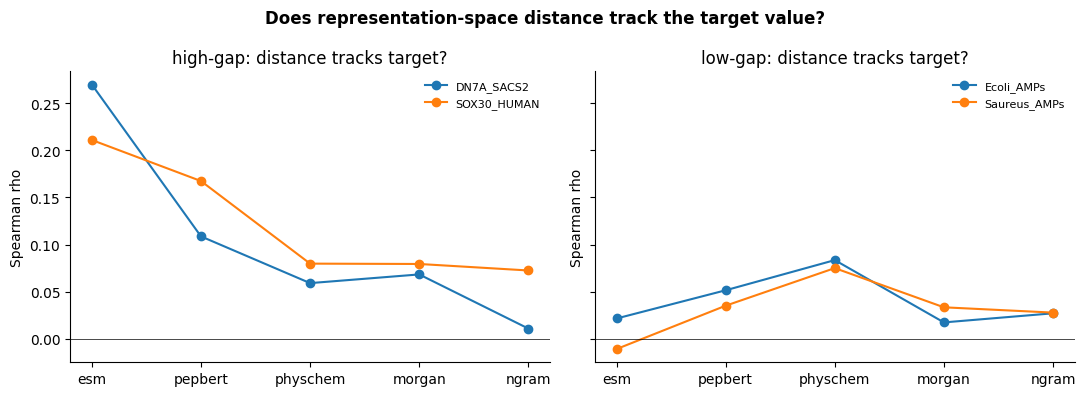

In [10]:
# Plot: distance-label correlation per representation, high-gap vs low-gap.
if len(geo):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for ax, grp in zip(axes, ['high-gap', 'low-gap']):
        sub = geo[geo['group'] == grp]
        for name, g in sub.groupby('Dataset'):
            ax.plot(g['Representation'], g['dist_label_rho'], 'o-', label=name)
        ax.set_title(f'{grp}: distance tracks target?'); ax.set_ylabel('Spearman rho')
        ax.axhline(0, color='k', lw=0.5); ax.legend(fontsize=8, frameon=False)
    fig.suptitle('Does representation-space distance track the target value?', fontweight='bold')
    fig.tight_layout(); ac.savefig(fig, 'embedding_geometry_rho'); plt.show()
